In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
import pandas as pd
from pathlib import Path

# Dataset path
DATA_PATH = Path("../data/da_realestate_listings.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (600, 15)


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold
0,PROP-0001,Chennai,CHE-Sector-18,4BHK,2507,13243,325.79,12,13,0,Unfurnished,2023-01-18,198,Rent,0
1,PROP-0002,Mumbai,MUM-Sector-5,Commercial,1404,7616,247.88,11,24,1,Fully,2023-07-30,123,Rent,0
2,PROP-0003,Delhi NCR,DEL-Sector-17,Plot,2673,3117,148.91,12,10,0,Fully,2023-05-05,164,Sale,0
3,PROP-0004,Pune,PUN-Sector-28,2BHK,1225,6940,108.03,11,20,0,Fully,2024-09-11,214,Sale,1
4,PROP-0005,Delhi NCR,DEL-Sector-3,Villa,2412,23280,363.66,16,4,1,Unfurnished,2023-05-23,171,Rent,1


In [3]:
# Dataset information
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        600 non-null    str    
 1   city              600 non-null    str    
 2   locality          600 non-null    str    
 3   type              600 non-null    str    
 4   area_sqft         600 non-null    int64  
 5   price_per_sqft    600 non-null    int64  
 6   total_price_lakh  600 non-null    float64
 7   age_years         600 non-null    int64  
 8   floor             600 non-null    int64  
 9   parking           600 non-null    int64  
 10  furnished         600 non-null    str    
 11  listed_date       600 non-null    str    
 12  days_on_market    600 non-null    int64  
 13  transaction_type  600 non-null    str    
 14  sold              600 non-null    int64  
dtypes: float64(1), int64(7), str(7)
memory usage: 102.6 KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,600,600,PROP-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,600,8,Chennai,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
locality,600,218,KOL-Sector-21,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,600,7,4BHK,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_sqft,600.0,NaN,NaN,NaN,2204.091667,1029.898702,406.0,1320.75,2195.5,3072.5,4000.0
price_per_sqft,600.0,NaN,NaN,NaN,10444.073333,6214.607603,2574.0,5771.5,8401.0,14124.75,23900.0
total_price_lakh,600.0,NaN,NaN,NaN,229.0991,183.746509,15.71,96.645,172.595,311.71,914.71
age_years,600.0,NaN,NaN,NaN,10.018333,6.133299,0.0,5.0,10.0,15.0,20.0
floor,600.0,NaN,NaN,NaN,12.458333,7.527241,0.0,6.75,13.0,19.0,25.0
parking,600.0,NaN,NaN,NaN,0.673333,0.469386,0.0,0.0,1.0,1.0,1.0



Column Names:
['listing_id', 'city', 'locality', 'type', 'area_sqft', 'price_per_sqft', 'total_price_lakh', 'age_years', 'floor', 'parking', 'furnished', 'listed_date', 'days_on_market', 'transaction_type', 'sold']


In [4]:
print("Missing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
display(df.dtypes)

Missing Values:


listing_id          0
city                0
locality            0
type                0
area_sqft           0
price_per_sqft      0
total_price_lakh    0
age_years           0
floor               0
parking             0
furnished           0
listed_date         0
days_on_market      0
transaction_type    0
sold                0
dtype: int64


Duplicate Rows: 0

Data Types:


listing_id              str
city                    str
locality                str
type                    str
area_sqft             int64
price_per_sqft        int64
total_price_lakh    float64
age_years             int64
floor                 int64
parking               int64
furnished               str
listed_date             str
days_on_market        int64
transaction_type        str
sold                  int64
dtype: object

In [5]:
print("Missing Values:")
display(df.isnull().sum())

print("Total Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDuplicate Listing IDs:", df["listing_id"].duplicated().sum())

Missing Values:


listing_id          0
city                0
locality            0
type                0
area_sqft           0
price_per_sqft      0
total_price_lakh    0
age_years           0
floor               0
parking             0
furnished           0
listed_date         0
days_on_market      0
transaction_type    0
sold                0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0

Duplicate Listing IDs: 0


In [6]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)


Numerical Columns:
['area_sqft', 'price_per_sqft', 'total_price_lakh', 'age_years', 'floor', 'parking', 'days_on_market', 'sold']

Categorical Columns:
['listing_id', 'city', 'locality', 'type', 'furnished', 'listed_date', 'transaction_type']


In [7]:
# Statistical summary
display(df[numerical_cols].describe().T)

# Unique values in numerical columns
print("\nUnique Values:")
display(df[numerical_cols].nunique())

# Check binary distribution of sold
print("\nSold Distribution:")
display(df["sold"].value_counts())

,count,mean,std,min,25%,50%,75%,max
area_sqft,600.0,2204.091667,1029.898702,406.00,1320.750,2195.500,3072.50,4000.00
price_per_sqft,600.0,10444.073333,6214.607603,2574.00,5771.500,8401.000,14124.75,23900.00
total_price_lakh,600.0,229.099100,183.746509,15.71,96.645,172.595,311.71,914.71
age_years,600.0,10.018333,6.133299,0.00,5.000,10.000,15.00,20.00
floor,600.0,12.458333,7.527241,0.00,6.750,13.000,19.00,25.00
parking,600.0,0.673333,0.469386,0.00,0.000,1.000,1.00,1.00
days_on_market,600.0,183.700000,105.181201,1.00,90.750,185.500,272.00,365.00
sold,600.0,0.348333,0.476840,0.00,0.000,0.000,1.00,1.00



Unique Values:


area_sqft           546
price_per_sqft      588
total_price_lakh    596
age_years            21
floor                26
parking               2
days_on_market      305
sold                  2
dtype: int64


Sold Distribution:


sold
0    391
1    209
Name: count, dtype: int64

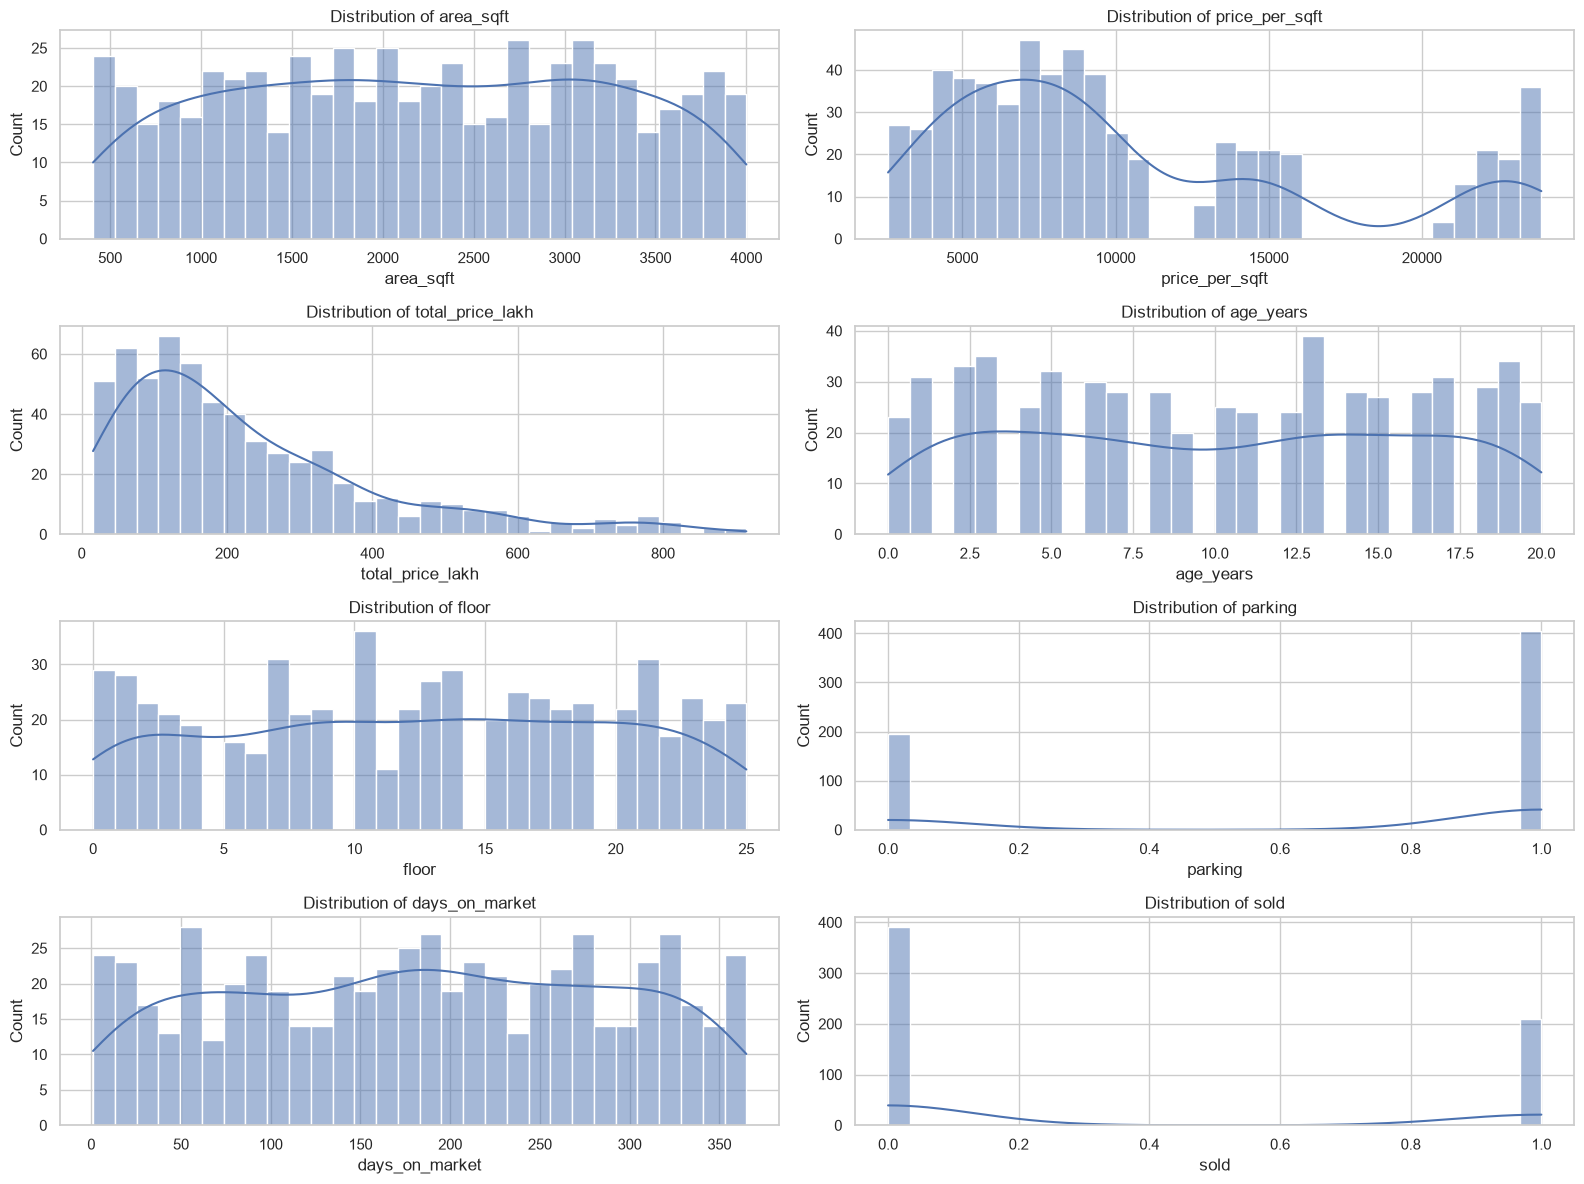

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 2, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

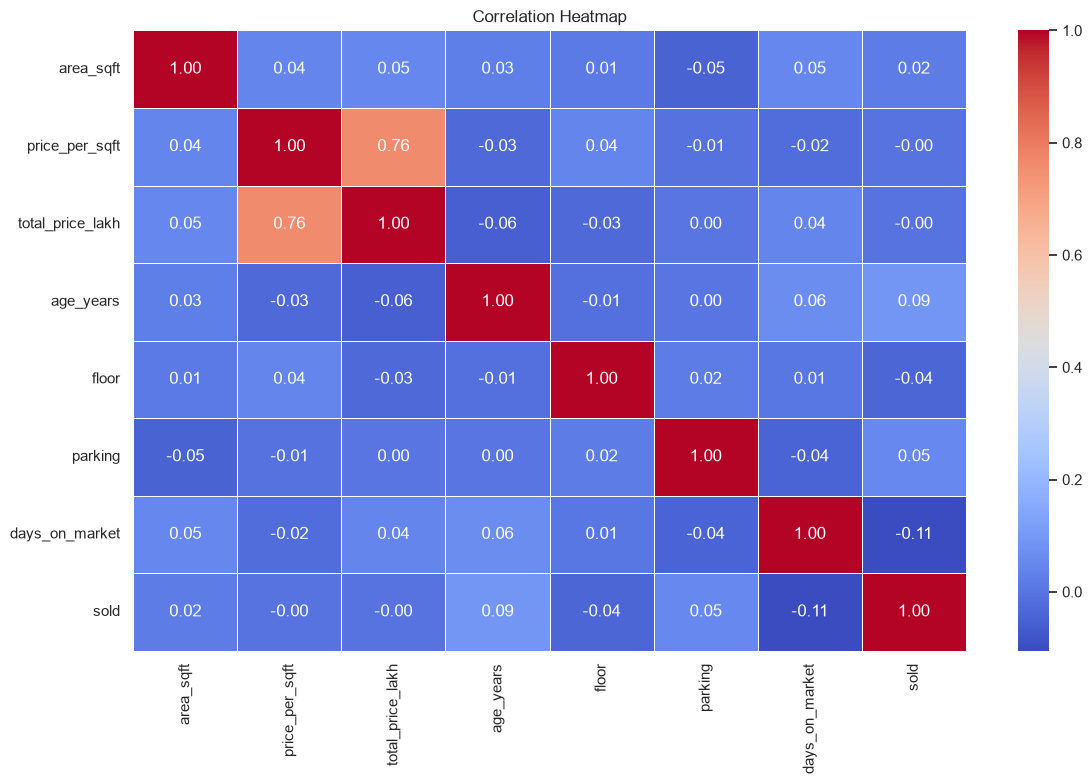

In [9]:
plt.figure(figsize=(12, 8))

correlation = df[numerical_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [10]:
# IQR Outlier Detection

outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,area_sqft,-1306.8750,5700.1250,0,0.00
1,price_per_sqft,-6758.3750,26654.6250,0,0.00
2,total_price_lakh,-225.9525,634.3075,28,4.67
3,age_years,-10.0000,30.0000,0,0.00
4,floor,-11.6250,37.3750,0,0.00
5,parking,-1.5000,2.5000,0,0.00
6,days_on_market,-181.1250,543.8750,0,0.00
7,sold,-1.5000,2.5000,0,0.00


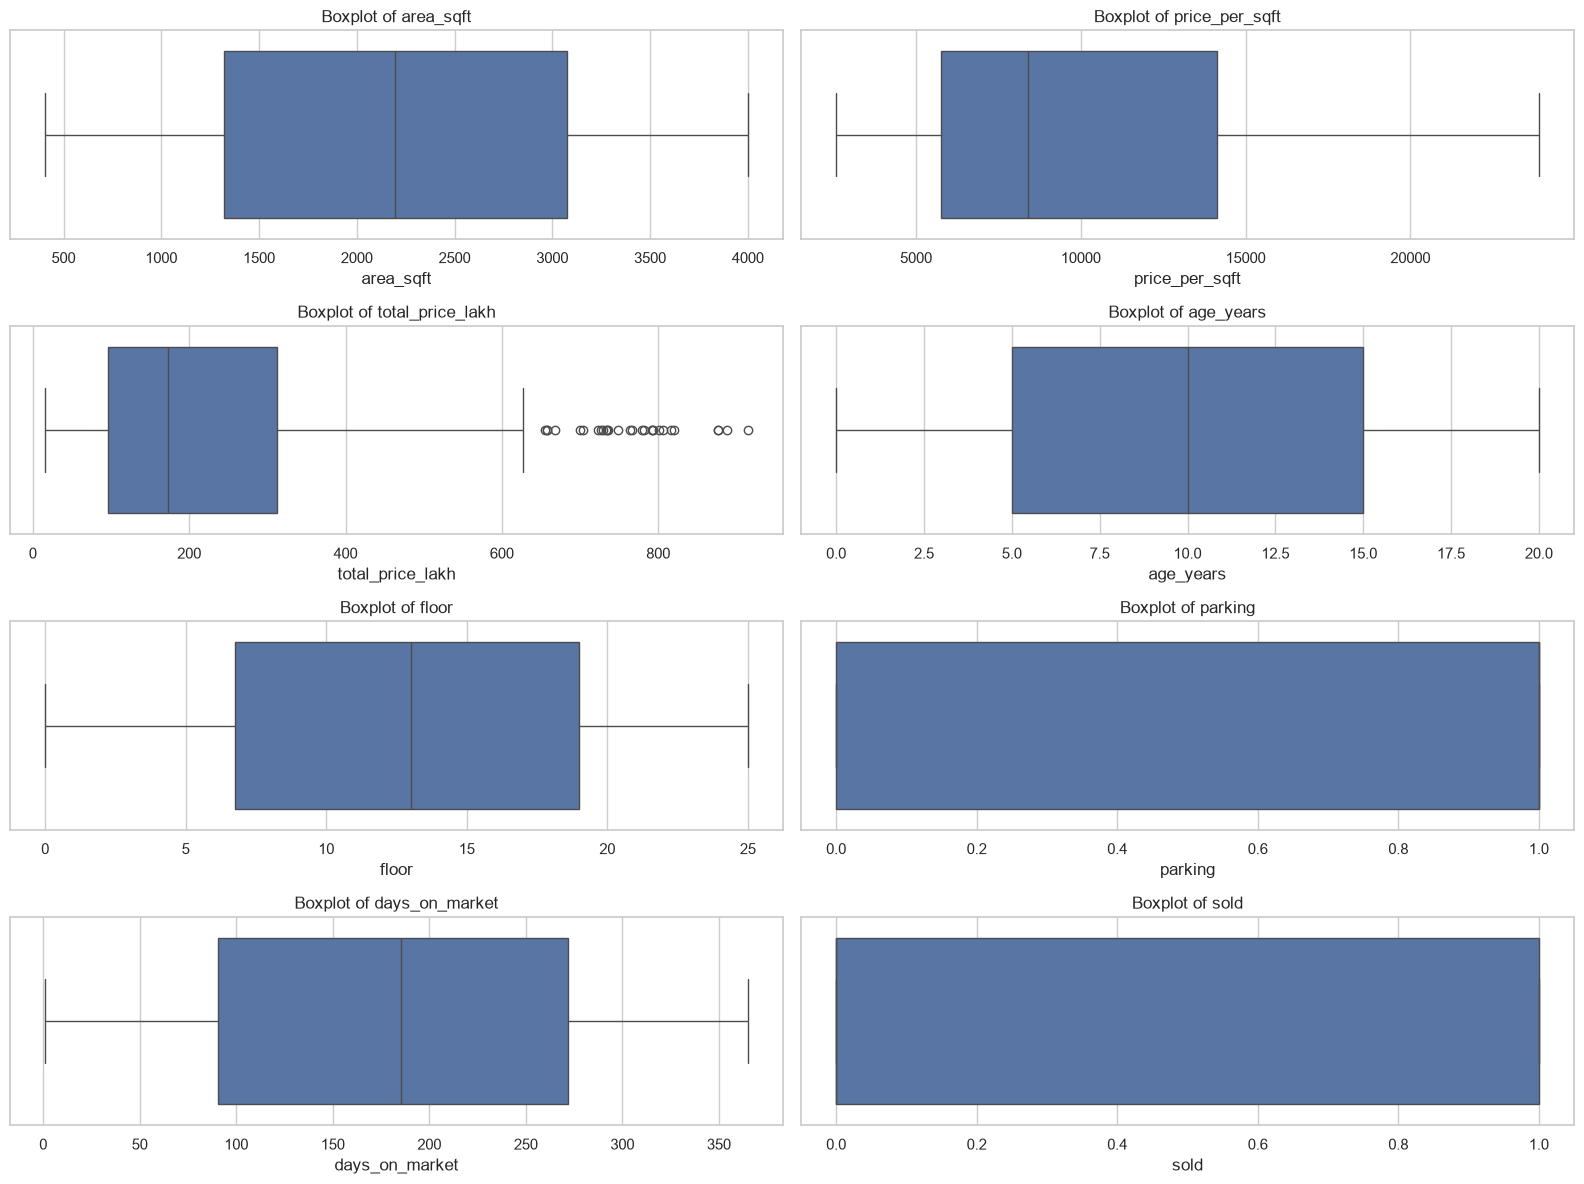

In [11]:
plt.figure(figsize=(16, 12))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 2, i)

    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [12]:
df["calculated_price_lakh"] = (
    df["area_sqft"] * df["price_per_sqft"]
) / 100000

df["price_difference"] = (
    df["total_price_lakh"] -
    df["calculated_price_lakh"]
)

display(
    df[
        [
            "area_sqft",
            "price_per_sqft",
            "total_price_lakh",
            "calculated_price_lakh",
            "price_difference"
        ]
    ].head(10)
)

,area_sqft,price_per_sqft,total_price_lakh,calculated_price_lakh,price_difference
0,2507,13243,325.79,332.00201,-6.21201
1,1404,7616,247.88,106.92864,140.95136
2,2673,3117,148.91,83.31741,65.59259
3,1225,6940,108.03,85.01500,23.01500
4,2412,23280,363.66,561.51360,-197.85360
5,1641,7291,200.69,119.64531,81.04469
6,1339,15804,469.22,211.61556,257.60444
7,2679,15586,127.04,417.54894,-290.50894
8,3797,14899,302.62,565.71503,-263.09503
9,2709,3629,50.76,98.30961,-47.54961


In [13]:
# Select numerical features for anomaly detection

features = [
    "area_sqft",
    "price_per_sqft",
    "age_years",
    "floor",
    "parking",
    "days_on_market"
]

X = df[features].copy()

print("Selected Features:")
print(features)

print("\nFeature Matrix Shape:", X.shape)

display(X.head())

Selected Features:
['area_sqft', 'price_per_sqft', 'age_years', 'floor', 'parking', 'days_on_market']

Feature Matrix Shape: (600, 6)


,area_sqft,price_per_sqft,age_years,floor,parking,days_on_market
0,2507,13243,12,13,0,198
1,1404,7616,11,24,1,123
2,2673,3117,12,10,0,164
3,1225,6940,11,20,0,214
4,2412,23280,16,4,1,171


In [14]:
print("Negative Values:")
display((X < 0).sum())

print("\nZero Values:")
display((X == 0).sum())

print("\nInfinite Values:")
display(np.isinf(X).sum())

Negative Values:


area_sqft         0
price_per_sqft    0
age_years         0
floor             0
parking           0
days_on_market    0
dtype: int64


Zero Values:


area_sqft           0
price_per_sqft      0
age_years          23
floor              29
parking           196
days_on_market      0
dtype: int64


Infinite Values:


area_sqft         0
price_per_sqft    0
age_years         0
floor             0
parking           0
days_on_market    0
dtype: int64

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("Scaling completed!")
display(X_scaled.head())

Scaling completed!


,area_sqft,price_per_sqft,age_years,floor,parking,days_on_market
0,0.294360,0.450754,0.323369,0.072021,-1.435697,0.136069
1,-0.777513,-0.455448,0.160189,1.534599,0.696526,-0.577581
2,0.455675,-1.179992,0.323369,-0.326864,-1.435697,-0.187452
3,-0.951461,-0.564315,0.160189,1.002752,-1.435697,0.288315
4,0.202041,2.067168,0.976091,-1.124634,0.696526,-0.120845


In [16]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    max_samples="auto"
)

# Train model and predict anomalies
df["anomaly_prediction"] = iso_forest.fit_predict(X_scaled)

# Convert predictions:
# -1 = Anomaly
#  1 = Normal

df["anomaly_label"] = df["anomaly_prediction"].map({
    1: "Normal",
    -1: "Anomaly"
})

print("Isolation Forest training completed!")

Isolation Forest training completed!


In [17]:
print("Anomaly Distribution:")
display(df["anomaly_label"].value_counts())

anomaly_count = (df["anomaly_prediction"] == -1).sum()
normal_count = (df["anomaly_prediction"] == 1).sum()

print("\nTotal Listings:", len(df))
print("Normal Listings:", normal_count)
print("Anomalies Detected:", anomaly_count)

print(
    "Anomaly Percentage:",
    round(anomaly_count / len(df) * 100, 2),
    "%"
)

Anomaly Distribution:


anomaly_label
Normal     570
Anomaly     30
Name: count, dtype: int64


Total Listings: 600
Normal Listings: 570
Anomalies Detected: 30
Anomaly Percentage: 5.0 %


In [18]:
anomalies = df[df["anomaly_prediction"] == -1].copy()

print("Detected Anomalous Listings:")
display(
    anomalies[
        [
            "listing_id",
            "city",
            "locality",
            "area_sqft",
            "price_per_sqft",
            "total_price_lakh",
            "age_years",
            "days_on_market",
            "anomaly_label"
        ]
    ].head(15)
)

Detected Anomalous Listings:


,listing_id,city,locality,area_sqft,price_per_sqft,total_price_lakh,age_years,days_on_market,anomaly_label
14,PROP-0015,Mumbai,MUM-Sector-15,3047,5011,93.79,1,1,Anomaly
18,PROP-0019,Kolkata,KOL-Sector-23,905,23570,555.54,19,9,Anomaly
45,PROP-0046,Delhi NCR,DEL-Sector-14,2558,22927,90.73,2,240,Anomaly
94,PROP-0095,Bengaluru,BEN-Sector-25,3364,15834,286.39,3,1,Anomaly
116,PROP-0117,Bengaluru,BEN-Sector-22,437,13400,581.19,0,259,Anomaly
141,PROP-0142,Pune,PUN-Sector-22,3752,15770,96.79,0,59,Anomaly
160,PROP-0161,Delhi NCR,DEL-Sector-9,774,15135,74.52,3,24,Anomaly
167,PROP-0168,Ahmedabad,AHM-Sector-5,406,9206,206.54,1,2,Anomaly
170,PROP-0171,Chennai,CHE-Sector-10,3536,22521,876.81,0,356,Anomaly
194,PROP-0195,Hyderabad,HYD-Sector-11,1856,21569,489.82,5,18,Anomaly


In [19]:


# Compare normal vs anomalous listings

comparison = df.groupby("anomaly_label")[features].mean().T

display(comparison)

anomaly_label,Anomaly,Normal
area_sqft,1994.000000,2215.149123
price_per_sqft,16815.000000,10108.761404
age_years,6.866667,10.184211
floor,12.000000,12.482456
parking,0.300000,0.692982
days_on_market,142.300000,185.878947


In [20]:
comparison["Difference"] = (
    comparison["Anomaly"] - comparison["Normal"]
)

display(comparison.sort_values(
    by="Difference",
    key=abs,
    ascending=False
))

anomaly_label,Anomaly,Normal,Difference
price_per_sqft,16815.000000,10108.761404,6706.238596
area_sqft,1994.000000,2215.149123,-221.149123
days_on_market,142.300000,185.878947,-43.578947
age_years,6.866667,10.184211,-3.317544
floor,12.000000,12.482456,-0.482456
parking,0.300000,0.692982,-0.392982


In [21]:
# Compare average feature values
comparison = df.groupby("anomaly_label")[features].mean().T

print("Normal vs Anomalous Listings:")
display(comparison.round(2))

# Calculate absolute differences
comparison["Difference"] = (
    comparison["Anomaly"] - comparison["Normal"]
)

print("\nFeature Differences:")
display(
    comparison.sort_values(
        by="Difference",
        key=abs,
        ascending=False
    ).round(2)
)

Normal vs Anomalous Listings:


anomaly_label,Anomaly,Normal
area_sqft,1994.00,2215.15
price_per_sqft,16815.00,10108.76
age_years,6.87,10.18
floor,12.00,12.48
parking,0.30,0.69
days_on_market,142.30,185.88



Feature Differences:


anomaly_label,Anomaly,Normal,Difference
price_per_sqft,16815.00,10108.76,6706.24
area_sqft,1994.00,2215.15,-221.15
days_on_market,142.30,185.88,-43.58
age_years,6.87,10.18,-3.32
floor,12.00,12.48,-0.48
parking,0.30,0.69,-0.39


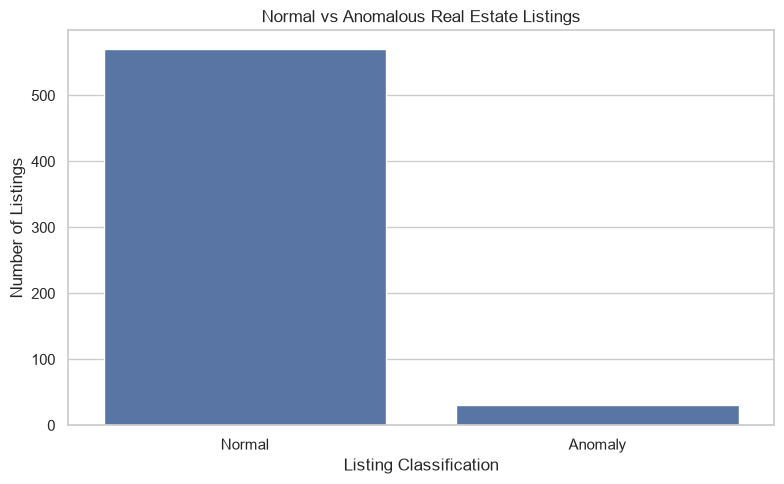

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="anomaly_label"
)

plt.title("Normal vs Anomalous Real Estate Listings")
plt.xlabel("Listing Classification")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

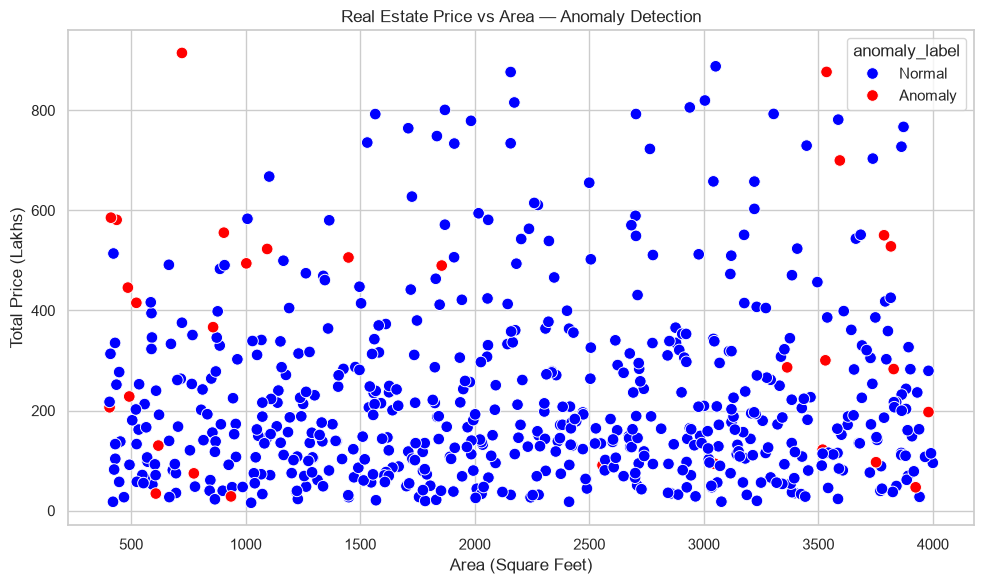

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y="total_price_lakh",
    hue="anomaly_label",
    palette={
        "Normal": "blue",
        "Anomaly": "red"
    },
    s=70
)

plt.title("Real Estate Price vs Area — Anomaly Detection")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Total Price (Lakhs)")

plt.tight_layout()
plt.show()

In [24]:
# Calculate anomaly scores
df["anomaly_score"] = -iso_forest.decision_function(X_scaled)

# Sort by highest anomaly score
ranked_anomalies = df.sort_values(
    by="anomaly_score",
    ascending=False
)

print("Top 15 Most Unusual Listings:")

display(
    ranked_anomalies[
        [
            "listing_id",
            "city",
            "area_sqft",
            "price_per_sqft",
            "total_price_lakh",
            "anomaly_score",
            "anomaly_label"
        ]
    ].head(15)
)

Top 15 Most Unusual Listings:


,listing_id,city,area_sqft,price_per_sqft,total_price_lakh,anomaly_score,anomaly_label
264,PROP-0265,Mumbai,3519,22934,121.84,0.036952,Anomaly
503,PROP-0504,Mumbai,722,22325,914.71,0.030219,Anomaly
454,PROP-0455,Ahmedabad,412,23395,585.52,0.028449,Anomaly
412,PROP-0413,Kolkata,3594,23786,699.86,0.027950,Anomaly
253,PROP-0254,Kolkata,619,4692,130.02,0.021073,Anomaly
305,PROP-0306,Kolkata,1003,21256,494.21,0.019618,Anomaly
482,PROP-0483,Pune,492,23389,228.12,0.018932,Anomaly
421,PROP-0422,Chennai,3531,14799,300.42,0.018191,Anomaly
284,PROP-0285,Pune,3817,23161,528.16,0.017512,Anomaly
194,PROP-0195,Hyderabad,1856,21569,489.82,0.017199,Anomaly


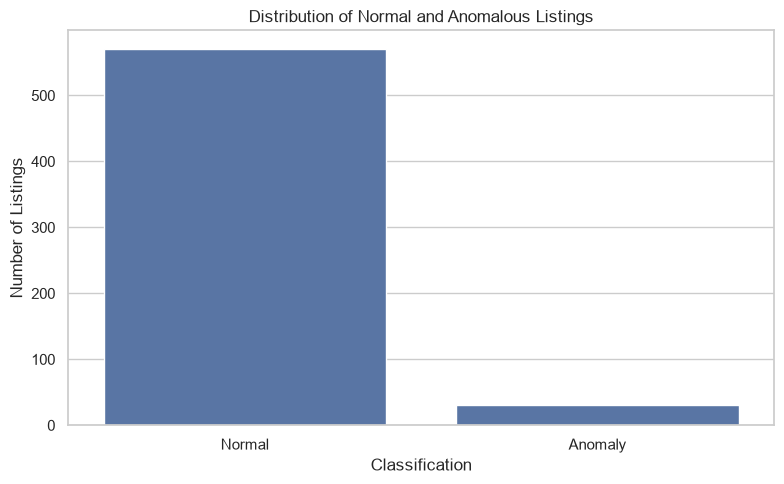

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="anomaly_label"
)

plt.title("Distribution of Normal and Anomalous Listings")
plt.xlabel("Classification")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

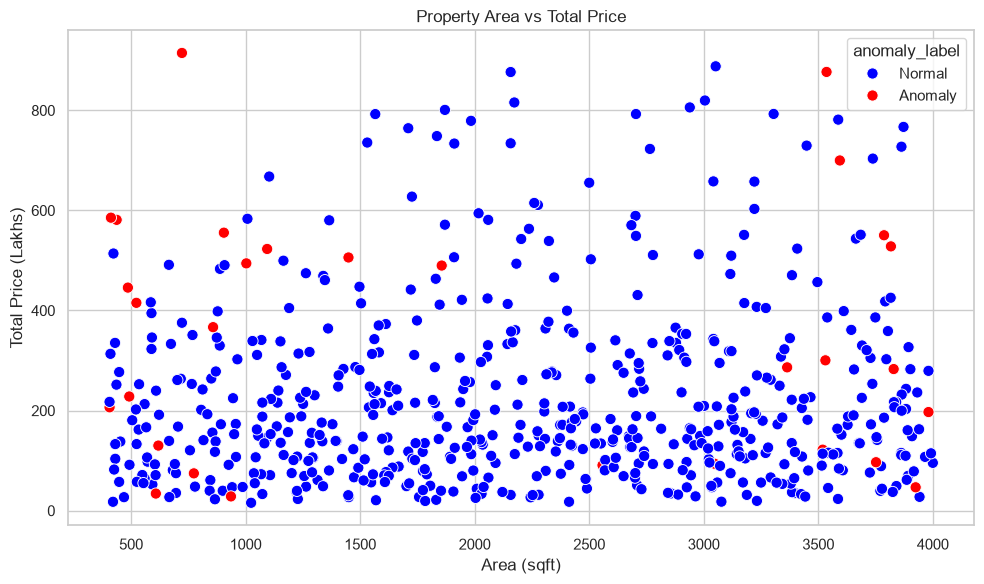

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y="total_price_lakh",
    hue="anomaly_label",
    palette={"Normal": "blue", "Anomaly": "red"},
    s=65
)

plt.title("Property Area vs Total Price")
plt.xlabel("Area (sqft)")
plt.ylabel("Total Price (Lakhs)")

plt.tight_layout()
plt.show()

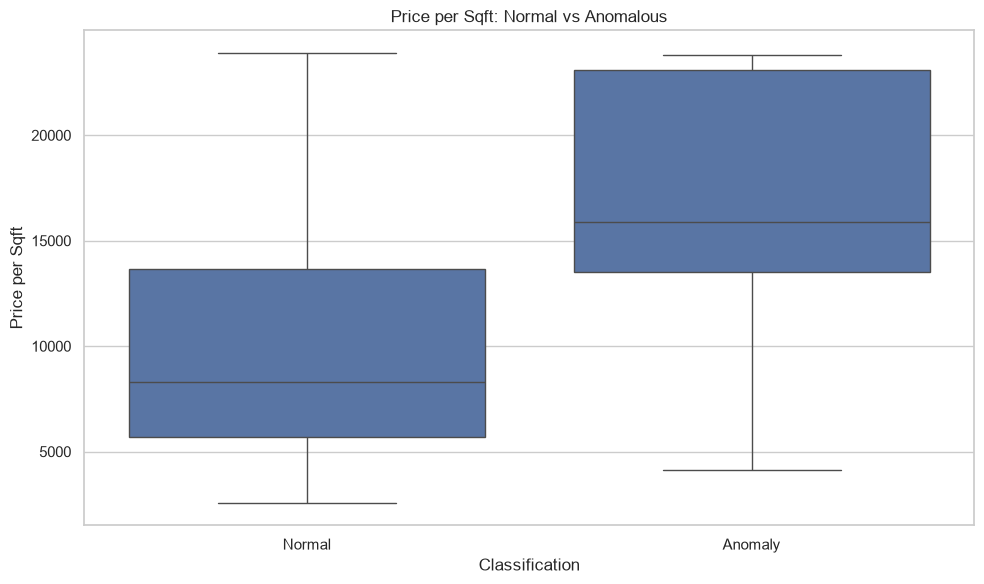

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="anomaly_label",
    y="price_per_sqft"
)

plt.title("Price per Sqft: Normal vs Anomalous")
plt.xlabel("Classification")
plt.ylabel("Price per Sqft")

plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export all listings with anomaly labels and scores
df.to_csv(
    OUTPUT_DIR / "realestate_anomaly_results.csv",
    index=False
)

# Export only anomalous listings
anomalies = df[df["anomaly_label"] == "Anomaly"].copy()

anomalies.to_csv(
    OUTPUT_DIR / "detected_anomalies.csv",
    index=False
)

# Export top 15 most unusual listings
ranked_anomalies.head(15).to_csv(
    OUTPUT_DIR / "top_15_anomalies.csv",
    index=False
)

print("Results exported successfully!")

print("Files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)

Results exported successfully!
Files:
detected_anomalies.csv
realestate_anomaly_results.csv
top_15_anomalies.csv


## 28. Business Insights and Conclusion

### Business Insights
- Applied the Isolation Forest algorithm to identify unusual patterns in real-estate listings.
- Analyzed 600 property records and detected 30 anomalies, representing 5% of the dataset.
- Anomalous listings showed a higher average price per square foot (16,815) compared with normal listings (10,108.76).
- Anomalous listings had shorter average days on market (142.30 days) compared with normal listings (185.88 days).
- Lower parking availability was observed among anomalous listings.
- Identified inconsistencies between recorded property prices and calculated prices, highlighting the need for additional data validation.

### Conclusion
Isolation Forest successfully identified unusual real-estate listings using property area, price per square foot, property age, floor, parking availability, and days on market.

The analysis demonstrates how unsupervised machine learning can help identify potentially unusual property listings, prioritize records for manual investigation, and improve real-estate data quality.

The detected anomalies should be treated as observations requiring further investigation rather than confirmed fraudulent listings.

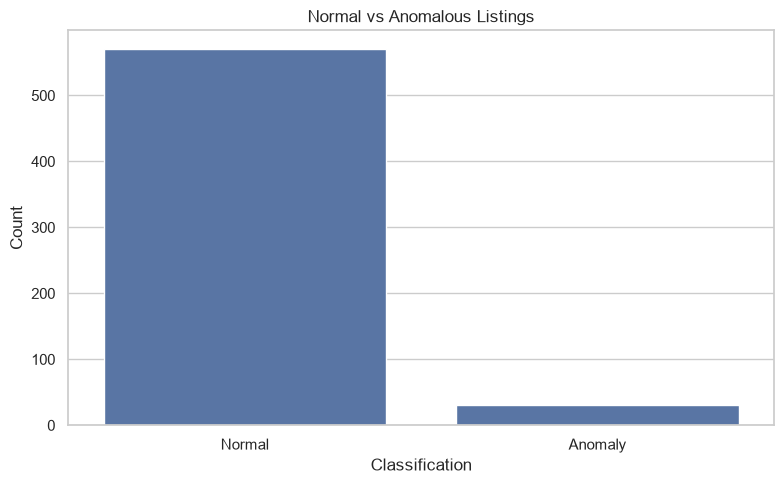

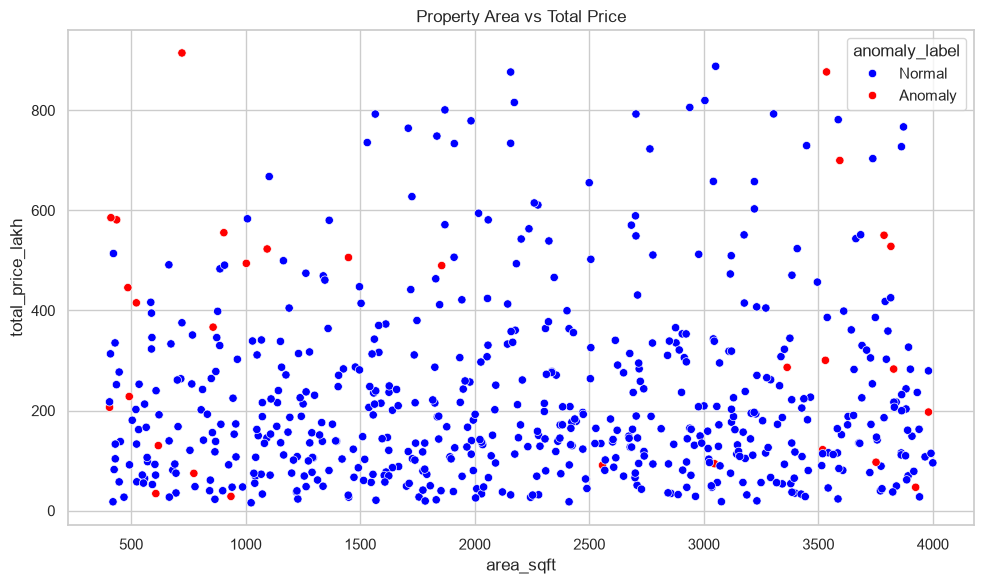

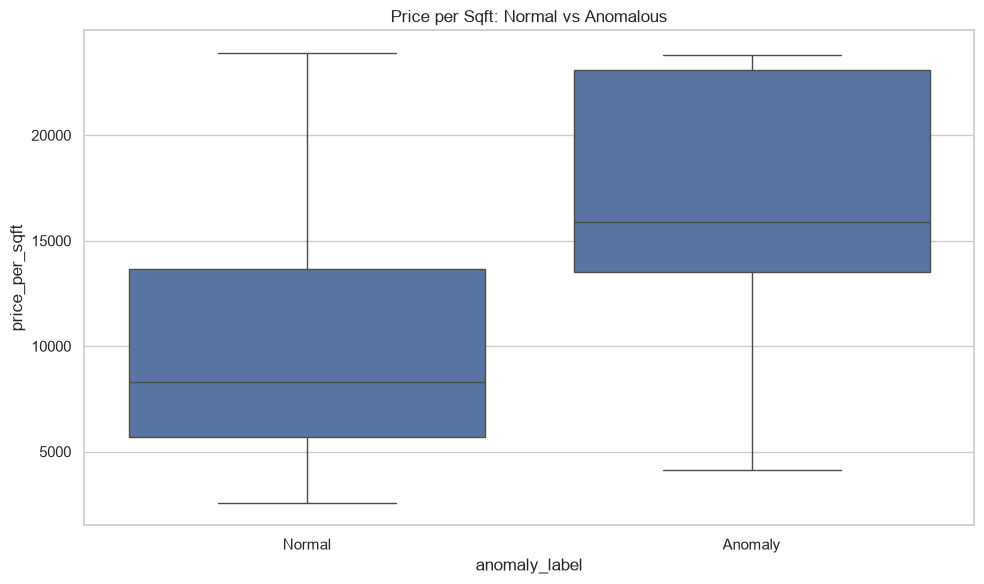

All visualizations saved successfully!


In [29]:
from pathlib import Path

EVIDENCE_DIR = Path("../evidence")
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Anomaly distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="anomaly_label")
plt.title("Normal vs Anomalous Listings")
plt.xlabel("Classification")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(EVIDENCE_DIR / "anomaly_distribution.png", dpi=300)
plt.show()

# 2. Area vs price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="area_sqft",
    y="total_price_lakh",
    hue="anomaly_label",
    palette={"Normal": "blue", "Anomaly": "red"}
)
plt.title("Property Area vs Total Price")
plt.tight_layout()
plt.savefig(EVIDENCE_DIR / "area_vs_price.png", dpi=300)
plt.show()

# 3. Price per sqft
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="anomaly_label", y="price_per_sqft")
plt.title("Price per Sqft: Normal vs Anomalous")
plt.tight_layout()
plt.savefig(EVIDENCE_DIR / "price_per_sqft.png", dpi=300)
plt.show()

print("All visualizations saved successfully!")

In [30]:
print("OUTPUT FILES:")

for file in OUTPUT_DIR.iterdir():
    print(file.name, "-", file.stat().st_size, "bytes")

print("\nEVIDENCE FILES:")

for file in EVIDENCE_DIR.iterdir():
    print(file.name, "-", file.stat().st_size, "bytes")

OUTPUT FILES:
detected_anomalies.csv - 4735 bytes
realestate_anomaly_results.csv - 88863 bytes
top_15_anomalies.csv - 2482 bytes

EVIDENCE FILES:
anomaly_distribution.png - 57187 bytes
area_vs_price.png - 353845 bytes
price_per_sqft.png - 72271 bytes
